# AI-Based Crop Disease Detection and Advisory (v2: with Not_a_leaf class)

Before running: put your own non-leaf photos (selfies, hands, road signs, objects, fake leaves) in the `not_leaf_images` folder next to this notebook.

## 1. Imports and CPU setup

In [1]:
import os

import json, random, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())

TensorFlow: 2.21.0
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2. Configuration

The dataset (*PlantVillage* from Kaggle) is downloaded automatically in the next cell, so you don't need to download anything by hand.

Folder names differ between versions of the dataset, so classes are picked using **keywords**. Edit `CLASS_KEYWORDS` if you want other classes.

In [2]:
DATASET_DIR = None                 # filled automatically by the Kaggle download cell below

# keyword(s) that must appear in the folder name (lower-case). One entry = one class.
CLASS_KEYWORDS = [
    ("tomato", "early_blight"),
    ("tomato", "late_blight"),
    ("tomato", "healthy"),
    ("potato", "early_blight"),
    ("pepper", "bacterial_spot"),
]

IMG_SIZE = (160, 160)          # smaller than 224 so CPU training is faster
BATCH_SIZE = 32
MAX_IMAGES_PER_CLASS = 600     # cap for speed; raise it (or set None) if your PC is fast
EPOCHS_HEAD = 8                # training with frozen MobileNetV2
# ---- extra class "Not_a_leaf": teaches the model to reject non-leaf images
NOT_LEAF_DIR = "not_leaf_images"   # put YOUR OWN negative photos here (selfies, hands, road signs, fake leaves, objects)
NOT_LEAF_TOTAL = 600               # total images for the Not_a_leaf class (your photos first, scenes fill the rest)
USE_IMAGENET_MINI = True           # download ~4 GB of everyday-object photos (animals, objects, people, rooms) as extra negatives
OUTPUT_DIR = "model_output"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(NOT_LEAF_DIR, exist_ok=True)

### Download dataset from Kaggle (automatic)
Uses `kagglehub` to download the public PlantVillage dataset (`emmarex/plantdisease`). The first run downloads it once; later runs reuse the cached copy. If Kaggle asks for login, see the note under this cell.

In [3]:
# pip install kagglehub   (run once if the import below fails)
import kagglehub

root = kagglehub.dataset_download("emmarex/plantdisease")
print("Downloaded to:", root)

# the class folders are sometimes nested one or two levels deep, so find the folder that holds them
best, best_count = root, 0
for dirpath, dirnames, _ in os.walk(root):
    if len(dirnames) > best_count:
        best, best_count = dirpath, len(dirnames)
DATASET_DIR = best
print("Using DATASET_DIR =", DATASET_DIR,
 f"({best_count} class folders)")

Downloaded to: C:\Users\suhan\.cache\kagglehub\datasets\emmarex\plantdisease\versions\1
Using DATASET_DIR = C:\Users\suhan\.cache\kagglehub\datasets\emmarex\plantdisease\versions\1\PlantVillage (16 class folders)


### Negative images for the `Not_a_leaf` class
The model can only answer with classes it has seen, so without this class a selfie or a road sign is forced into a disease class. Here we collect non-leaf images from two sources:
1. **Your own photos** in the `not_leaf_images` folder (selfies, hands, road signs, objects, **fake/plastic leaves**). These matter most.
2. **Scene photos** (buildings, glacier, mountain, sea, street) from the Kaggle *Intel Image Classification* dataset to add variety.

In [4]:
import glob
img_exts = (".jpg", ".jpeg", ".png")

# 0) auto-generate blank / plain / gradient / noisy backgrounds (PlantVillage leaves have plain backgrounds,
#    so the model must learn that "plain background alone" is NOT a leaf)
from PIL import Image, ImageFilter
synth_dir = os.path.join(NOT_LEAF_DIR, "synthetic_blank")
os.makedirs(synth_dir, exist_ok=True)
if len(glob.glob(os.path.join(synth_dir, "*.jpg"))) < 100:
    rng = np.random.default_rng(SEED)
    for n in range(120):
        kind = n % 4
        if kind == 0:      # plain colour (white, grey, black, beige, wall colours)
            arr = np.ones((224, 224, 3)) * rng.integers(0, 256, size=3)
        elif kind == 1:    # smooth gradient
            a, b = rng.integers(0, 256, size=3), rng.integers(0, 256, size=3)
            t = np.linspace(0, 1, 224)[None, :, None]
            arr = (a * (1 - t) + b * t) * np.ones((224, 1, 1))
        elif kind == 2:    # plain colour + light noise
            arr = np.ones((224, 224, 3)) * rng.integers(0, 256, size=3) + rng.normal(0, 12, (224, 224, 3))
        else:              # blurred random blobs (like an out-of-focus room)
            small = rng.integers(0, 256, size=(6, 6, 3)).astype("uint8")
            arr = np.asarray(Image.fromarray(small).resize((224, 224), Image.BICUBIC).filter(ImageFilter.GaussianBlur(8)))
        Image.fromarray(np.clip(arr, 0, 255).astype("uint8")).save(os.path.join(synth_dir, f"blank_{n}.jpg"))
    print("Generated 120 blank/plain background images")

# 1) your own negative photos (any sub-folder inside NOT_LEAF_DIR)
own_files = [f for f in glob.glob(os.path.join(NOT_LEAF_DIR, "**", "*"), recursive=True)
             if f.lower().endswith(img_exts)]
print("Your own Not_a_leaf images:", len(own_files))
print("(Your own photos are optional. 10 to 20 of your face, room and desk help a lot, but are not required.)")

# 2) scene photos from Kaggle (non-plant scenes only; 'forest' is skipped on purpose)
scene_root = kagglehub.dataset_download("puneet6060/intel-image-classification")
SCENE_FOLDERS = {"buildings", "glacier", "mountain", "sea", "street"}
scene_files = []
for dirpath, dirnames, files in os.walk(scene_root):
    if os.path.basename(dirpath).lower() in SCENE_FOLDERS and "seg_train" in dirpath.lower().replace("\\", "/"):
        scene_files += [os.path.join(dirpath, f) for f in files if f.lower().endswith(img_exts)]
print("Scene images available:", len(scene_files))

# 3) everyday objects, animals, people, rooms from ImageNet-mini (optional, big download of about 4 GB, cached after first time)
imagenet_files = []
if USE_IMAGENET_MINI:
    try:
        inet_root = kagglehub.dataset_download("ifigotin/imagenetmini-1000")
        for dirpath, dirnames, files in os.walk(inet_root):
            if "train" in dirpath.lower().replace("\\", "/").split("/"):
                imagenet_files += [os.path.join(dirpath, f) for f in files if f.lower().endswith(img_exts + (".jpeg",))]
        print("ImageNet-mini images available:", len(imagenet_files))
    except Exception as e:
        print("Could not download ImageNet-mini, continuing without it:", e)

random.shuffle(own_files); random.shuffle(scene_files); random.shuffle(imagenet_files)
own_files = own_files[:NOT_LEAF_TOTAL]
remaining = max(0, NOT_LEAF_TOTAL - len(own_files))
n_inet = min(len(imagenet_files), int(remaining * 0.6))          # 60% everyday objects
n_scene = remaining - n_inet                                        # rest: scenes
not_leaf_paths = own_files + imagenet_files[:n_inet] + scene_files[:n_scene]
print("Total Not_a_leaf images used:", len(not_leaf_paths))

Your own Not_a_leaf images: 120
(Your own photos are optional. 10 to 20 of your face, room and desk help a lot, but are not required.)
Scene images available: 11763
ImageNet-mini images available: 34745
Total Not_a_leaf images used: 600


## 3. Dataset preparation: find classes and image paths

In [5]:
def norm(s):
    return s.lower().replace("-", "_").replace(" ", "_")

all_folders = sorted([d for d in os.listdir(DATASET_DIR)
                      if os.path.isdir(os.path.join(DATASET_DIR, d))])
print("Folders found in dataset:", len(all_folders))

selected = []
for kws in CLASS_KEYWORDS:
    match = [f for f in all_folders if all(k in norm(f).replace("__", "_").replace("___", "_") for k in kws)]
    if not match:
        print("WARNING: no folder found for", kws)
    else:
        selected.append(match[0])

print("Selected classes:")
for s in selected: print("  -", s)
assert len(selected) >= 2, "Check DATASET_DIR and CLASS_KEYWORDS"

exts = (".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG")
paths, labels = [], []
for idx, folder in enumerate(selected):
    files = [f for f in glob.glob(os.path.join(DATASET_DIR, folder, "*")) if f.endswith(exts)]
    random.shuffle(files)
    if MAX_IMAGES_PER_CLASS:
        files = files[:MAX_IMAGES_PER_CLASS]
    paths += files
    labels += [idx] * len(files)

# ---- add the Not_a_leaf class (last label)
paths += not_leaf_paths
labels += [len(selected)] * len(not_leaf_paths)
class_names = selected + ["Not_a_leaf"]
NUM_CLASSES = len(class_names)
df = pd.DataFrame({"path": paths, "label": labels})
df["class"] = df["label"].map(lambda i: class_names[i])
print("\nTotal images:", len(df))
print(df["class"].value_counts())

Folders found in dataset: 16
Selected classes:
  - Tomato_Early_blight
  - Tomato_Late_blight
  - Tomato_healthy
  - Potato___Early_blight
  - Pepper__bell___Bacterial_spot

Total images: 3600
class
Tomato_Early_blight              600
Tomato_Late_blight               600
Tomato_healthy                   600
Potato___Early_blight            600
Pepper__bell___Bacterial_spot    600
Not_a_leaf                       600
Name: count, dtype: int64


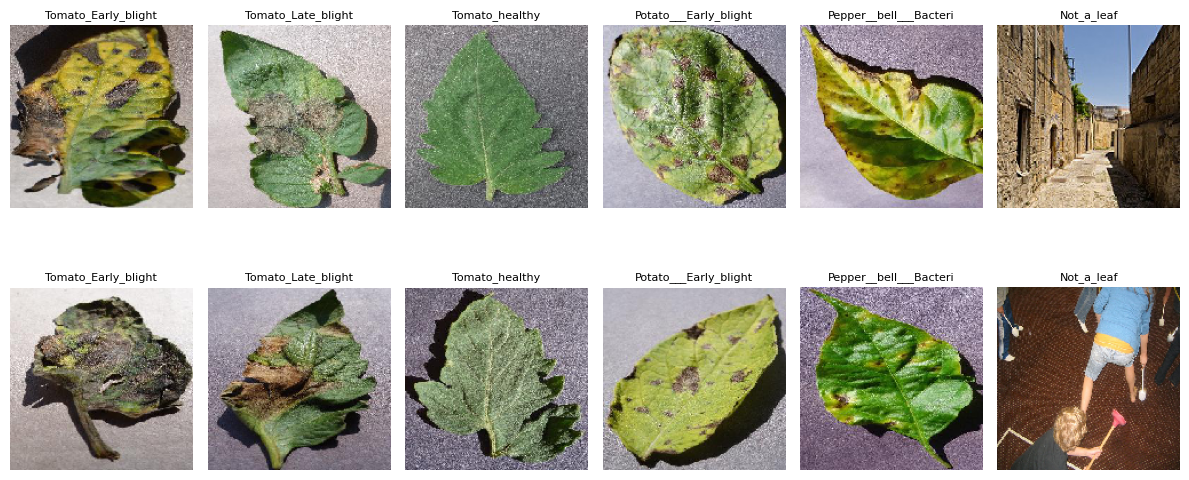

In [6]:
# Plot sample images from each class
plt.figure(figsize=(12, 6))
for i, cname in enumerate(class_names):
    sample = df[df["class"] == cname].sample(2, random_state=1)
    for j, p in enumerate(sample["path"]):
        plt.subplot(2, NUM_CLASSES, j * NUM_CLASSES + i + 1)
        plt.imshow(keras.utils.load_img(p, target_size=IMG_SIZE))
        plt.title(cname[:22], fontsize=8); plt.axis("off")
plt.tight_layout(); plt.show()

In [7]:
# Split the dataset into train, validation, and test sets (70% train, 15% validation, 15% test)
train_df, temp_df = train_test_split(
    df, test_size=0.30,
    stratify=df["label"],
    random_state=SEED)

val_df, test_df = train_test_split(
    temp_df, test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED)
    
print("Train:", len(train_df), "| Val:", len(val_df), "| Test:", len(test_df))

Train: 2520 | Val: 540 | Test: 540


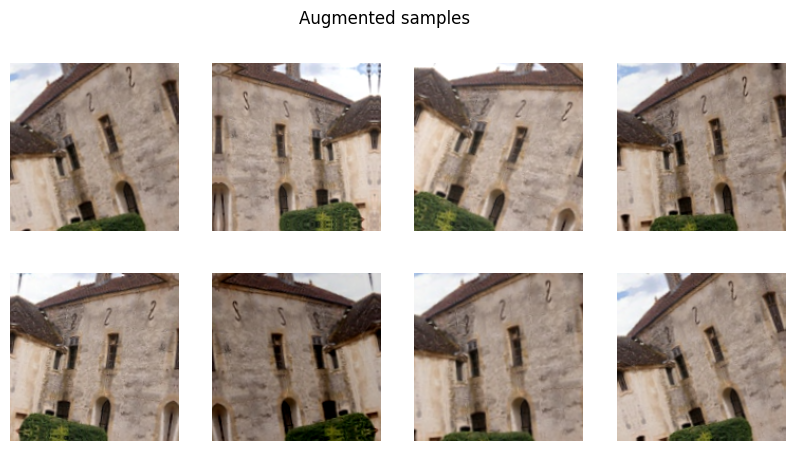

In [8]:
# Preprocessing and data augmentation
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img.set_shape((*IMG_SIZE, 3))
    return img, tf.one_hot(label, NUM_CLASSES)

def make_ds(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((frame["path"].values, frame["label"].values))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_ds(train_df, training=True)
val_ds   = make_ds(val_df)
test_ds  = make_ds(test_df)

augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.15, value_range=(0, 255)),
], name="augmentation")

# preview augmentation
imgs, _ = next(iter(train_ds))
plt.figure(figsize=(10, 5))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    aug = augmentation(imgs[:1], training=True)[0]
    plt.imshow(tf.cast(aug, tf.uint8)); plt.axis("off")
plt.suptitle("Augmented samples"); plt.show()

In [10]:
# MovibeNetV2 model (transfer learning)
base_model = MobileNetV2(input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet")
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = augmentation(inputs)                       # active only during training
x = layers.Rescaling(1/127.5, offset=-1, name="mobilenet_preprocess")(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs, name="crop_disease_mobilenetv2")

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "crop_disease_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocess            │ (None, 160, 160, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [11]:
# Train the model
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, callbacks=callbacks)

Epoch 1/8


c:\Users\suhan\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


79/79 ━━━━━━━━━━━━━━━━━━━━ 59s 612ms/step - accuracy: 0.7373 - loss: 0.7329 - val_accuracy: 0.9037 - val_loss: 0.3010 - learning_rate: 0.0010
Epoch 2/8
79/79 ━━━━━━━━━━━━━━━━━━━━ 42s 532ms/step - accuracy: 0.9028 - loss: 0.2873 - val_accuracy: 0.9389 - val_loss: 0.2087 - learning_rate: 0.0010
Epoch 3/8
79/79 ━━━━━━━━━━━━━━━━━━━━ 50s 633ms/step - accuracy: 0.9202 - loss: 0.2260 - val_accuracy: 0.9481 - val_loss: 0.1731 - learning_rate: 0.0010
Epoch 4/8
79/79 ━━━━━━━━━━━━━━━━━━━━ 48s 612ms/step - accuracy: 0.9425 - loss: 0.1883 - val_accuracy: 0.9481 - val_loss: 0.1588 - learning_rate: 0.0010
Epoch 5/8
79/79 ━━━━━━━━━━━━━━━━━━━━ 45s 565ms/step - accuracy: 0.9417 - loss: 0.1616 - val_accuracy: 0.9611 - val_loss: 0.1340 - learning_rate: 0.0010
Epoch 6/8
79/79 ━━━━━━━━━━━━━━━━━━━━ 39s 489ms/step - accuracy: 0.9504 - loss: 0.1343 - val_accuracy: 0.9537 - val_loss: 0.1382 - learning_rate: 0.0010
Epoch 7/8
79/79 ━━━━━━━━━━━━━━━━━━━━ 52s 662ms/step - accuracy: 0.9536 - loss: 0.1324 - val_accura

### Training curves

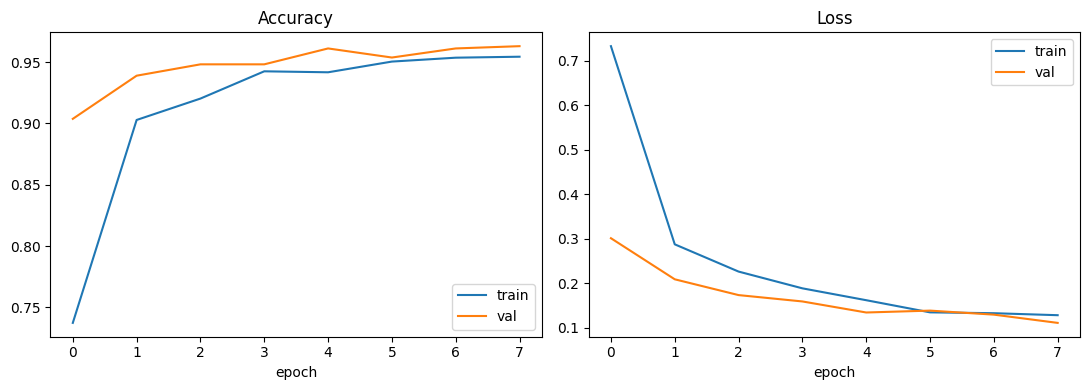

In [12]:
acc  = history.history["accuracy"];     val_acc  = history.history["val_accuracy"]
loss = history.history["loss"];         val_loss = history.history["val_loss"]

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1); plt.plot(acc, label="train"); plt.plot(val_acc, label="val")
plt.title("Accuracy"); plt.xlabel("epoch"); plt.legend()
plt.subplot(1, 2, 2); plt.plot(loss, label="train"); plt.plot(val_loss, label="val")
plt.title("Loss"); plt.xlabel("epoch"); plt.legend()
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/training_curves.png", dpi=150); plt.show()

17/17 ━━━━━━━━━━━━━━━━━━━━ 13s 740ms/step
Test accuracy: 0.95

                              precision    recall  f1-score   support

         Tomato_Early_blight     0.9481    0.8111    0.8743        90
          Tomato_Late_blight     0.8586    0.9444    0.8995        90
              Tomato_healthy     0.9375    1.0000    0.9677        90
       Potato___Early_blight     0.9885    0.9556    0.9718        90
Pepper__bell___Bacterial_spo     0.9780    0.9889    0.9834        90
                  Not_a_leaf     1.0000    1.0000    1.0000        90

                    accuracy                         0.9500       540
                   macro avg     0.9518    0.9500    0.9494       540
                weighted avg     0.9518    0.9500    0.9494       540



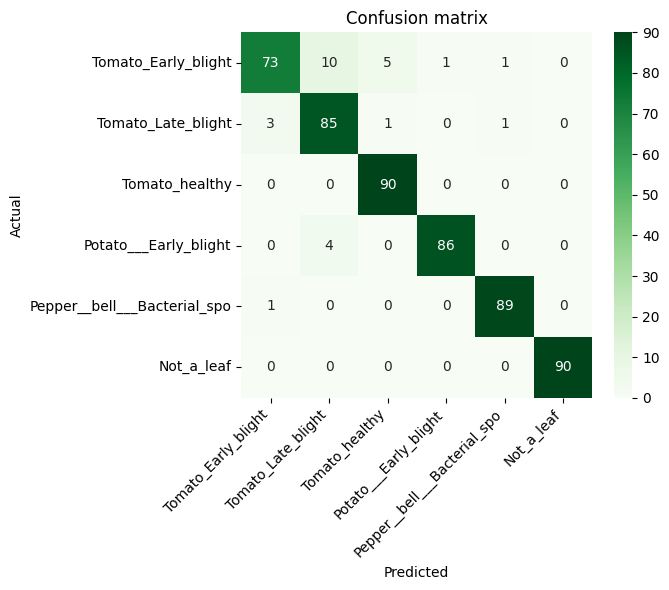

In [13]:
# Evaluation on the test set
y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test_ds])
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))
print()
short_names = [c[:28] for c in class_names]
print(classification_report(y_true, y_pred, target_names=short_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=short_names, yticklabels=short_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/confusion_matrix.png", dpi=150); plt.show()

In [14]:
model.save(f"{OUTPUT_DIR}/crop_disease_model.keras")

with open(f"{OUTPUT_DIR}/class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)
with open(f"{OUTPUT_DIR}/model_config.json", "w") as f:
    json.dump({"img_size": list(IMG_SIZE)}, f)

print("Saved to:", os.path.abspath(OUTPUT_DIR))

Saved to: c:\AI_projects\Crop-Disease Detection\model_output


In [15]:
ADVISORY_TEXT = {
    "early_blight": {
        "symptoms": "Brown spots with concentric rings on older leaves, yellowing around the spots.",
        "prevention": "Rotate crops, avoid overhead watering, remove infected plant debris, keep spacing for airflow.",
        "next_steps": "Remove badly affected leaves and consult a local agriculture officer about a suitable fungicide."
    },
    "late_blight": {
        "symptoms": "Dark, water-soaked patches on leaves that spread quickly, often with whitish growth in humid weather.",
        "prevention": "Use disease-free seed/seedlings, avoid wet foliage, ensure good drainage and airflow.",
        "next_steps": "Isolate or remove infected plants quickly and seek local expert advice on treatment."
    },
    "bacterial_spot": {
        "symptoms": "Small dark water-soaked spots on leaves that may turn brown or black, sometimes with yellow halos.",
        "prevention": "Use clean seed, avoid working in wet fields, rotate crops, disinfect tools.",
        "next_steps": "Remove infected leaves, avoid overhead irrigation and consult a local expert."
    },
    "not_a_leaf": {
        "symptoms": "-",
        "prevention": "-",
        "next_steps": "This image is not a supported crop leaf. Upload a clear photo of a single tomato, potato or bell pepper leaf."
    },
    "healthy": {
        "symptoms": "No visible disease symptoms detected.",
        "prevention": "Continue regular watering, balanced nutrition and routine monitoring of leaves.",
        "next_steps": "No action needed. Re-check if new spots or discoloration appear."
    },
}

rows = []
for cname in class_names:
    key = next((k for k in ADVISORY_TEXT if k in norm(cname).replace("__", "_")), None)
    info = ADVISORY_TEXT.get(key, {"symptoms": "-", "prevention": "-", "next_steps": "Consult a local expert."})
    rows.append({"class_name": cname, **info})

advisory_df = pd.DataFrame(rows)
advisory_df.to_csv(f"{OUTPUT_DIR}/advisory.csv", index=False)
advisory_df

,class_name,symptoms,prevention,next_steps
0,Tomato_Early_blight,Brown spots with concentric rings on older lea...,"Rotate crops, avoid overhead watering, remove ...",Remove badly affected leaves and consult a loc...
1,Tomato_Late_blight,"Dark, water-soaked patches on leaves that spre...","Use disease-free seed/seedlings, avoid wet fol...",Isolate or remove infected plants quickly and ...
2,Tomato_healthy,No visible disease symptoms detected.,"Continue regular watering, balanced nutrition ...",No action needed. Re-check if new spots or dis...
3,Potato___Early_blight,Brown spots with concentric rings on older lea...,"Rotate crops, avoid overhead watering, remove ...",Remove badly affected leaves and consult a loc...
4,Pepper__bell___Bacterial_spot,Small dark water-soaked spots on leaves that m...,"Use clean seed, avoid working in wet fields, r...","Remove infected leaves, avoid overhead irrigat..."
5,Not_a_leaf,-,-,This image is not a supported crop leaf. Uploa...


Actual   : Tomato_Early_blight


Predicted: Tomato_Early_blight                 85.53%
Predicted: Tomato_Late_blight                  13.25%
Predicted: Pepper__bell___Bacterial_spot       0.66%


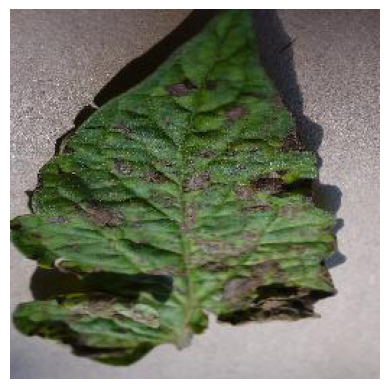

In [16]:
def predict_leaf(image_path, model=model, class_names=class_names, top_k=3):
    img = keras.utils.load_img(image_path, target_size=IMG_SIZE)
    arr = np.expand_dims(keras.utils.img_to_array(img), axis=0)
    probs = model.predict(arr, verbose=0)[0]
    order = np.argsort(probs)[::-1][:top_k]
    return [(class_names[i], float(probs[i])) for i in order]

# try a random test image
sample_path = test_df.sample(1, random_state=7).iloc[0]
print("Actual   :", sample_path["class"])
for name, p in predict_leaf(sample_path["path"]):
    print(f"Predicted: {name:35s} {p*100:.2f}%")
plt.imshow(keras.utils.load_img(sample_path["path"])); plt.axis("off"); plt.show()